# IEEE-CIS Fraud Detection

Задача исследования - изучить данные финансовых транзакций и выявить проблемы, которые необходимо учитывать при настройке AutoML для определения мошеннических операций (`isFraud`).

Источник: [IEEE-CIS Fraud Detection (Kaggle)](https://www.kaggle.com/competitions/ieee-fraud-detection/data). Исходные данные предоставлены Vesta Corporation.

Архив [ieee-fraud-detection.zip](https://drive.google.com/file/d/1qRvDwZR54C_vmY2f0UfQMf_aEYStVppc/view?usp=drive_link) должен находиться рядом с ноутбуком. CSV-файлы можно читать непосредственно из архива. Используются библиотеки `pandas`, `numpy`, `matplotlib`, `seaborn`.

Исследуются распределение таргета, пропуски, связи между таблицами, распределения признаков, временная структура, отличия train/test и возможные утечки.


## 1. Таблица

Проверяются состав архива, структура таблиц, типы данных и основные статистики. Для общей характеристики учитываются все столбцы. Распределения рассматриваются по основным группам признаков.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from zipfile import ZipFile
from IPython.display import display

sns.set_theme(style="whitegrid")
archive = ZipFile("ieee-fraud-detection.zip")


In [2]:
print("Файлы архива:")
for filename in archive.namelist():
    print(filename)


Файлы архива:
sample_submission.csv
test_identity.csv
test_transaction.csv
train_identity.csv
train_transaction.csv


In [3]:
for filename in archive.namelist():
    columns = pd.read_csv(archive.open(filename), nrows=0).columns
    print(filename, "- столбцов:", len(columns))


sample_submission.csv - столбцов: 2
test_identity.csv - столбцов: 41
test_transaction.csv - столбцов: 393
train_identity.csv - столбцов: 41
train_transaction.csv - столбцов: 394


Для подробных распределений используются признаки из разных групп. Для остальных столбцов отдельно проверяются пропуски, а также особенности структуры и изменений между train и test.

In [4]:
columns = [
    "TransactionID", "isFraud", "TransactionDT", "TransactionAmt", "ProductCD",
    "card1", "card2", "card3", "card4", "card5", "card6",
    "addr1", "addr2", "dist1", "dist2", "P_emaildomain", "R_emaildomain",
    "C1", "C2", "C13", "D1", "D4", "D7", "D15", "V1", "V100", "V200", "V300"
] + [f"M{i}" for i in range(1, 10)]

train = pd.read_csv(archive.open("train_transaction.csv"), usecols=columns)
identity = pd.read_csv(archive.open("train_identity.csv"))
print("Транзакции:", train.shape)
print("Identity:", identity.shape)
display(train.head())


Транзакции: (590540, 37)
Identity: (144233, 41)


,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,M4,M5,M6,M7,M8,M9,V1,V100,V200,V300
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,M2,F,T,NaN,NaN,NaN,1.0,0.0,NaN,0.0
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,M0,T,T,NaN,NaN,NaN,NaN,0.0,NaN,0.0
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,M0,F,F,F,F,F,1.0,0.0,NaN,0.0
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,M0,T,F,NaN,NaN,NaN,NaN,4.0,NaN,0.0
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,0.0


In [5]:
display(identity.head())
print("Типы полей identity:")
display(identity.dtypes.value_counts())

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


Типы полей identity:


float64    23
str        17
int64       1
Name: count, dtype: int64

In [6]:
print("Типы выбранных признаков:")
display(train.dtypes.value_counts().rename("Количество"))
display(train[["TransactionAmt", "TransactionDT", "card1", "D4"]].describe().T.round(2))

Типы выбранных признаков:


float64    19
str        14
int64       4
Name: Количество, dtype: int64

,count,mean,std,min,25%,50%,75%,max
TransactionAmt,590540.0,135.03,239.16,0.25,43.32,68.77,125.0,31937.39
TransactionDT,590540.0,7372311.31,4617223.65,86400.00,3027057.75,7306527.50,11246620.0,15811131.00
card1,590540.0,9898.73,4901.17,1000.00,6019.00,9678.00,14184.0,18396.00
D4,421618.0,140.00,191.10,-122.00,0.00,26.00,253.0,869.00


`TransactionDT` содержит относительное время в секундах, а не календарную дату. Большая часть признаков групп `C`, `D`, `M`, `V` обезличена. Отсутствие расшифровки ограничивает проверку их доступности на момент прогноза.


## 2. Таргет

Проверяются количество и доля мошеннических операций. При редком положительном классе accuracy может давать завышенное представление о полезности модели.


isFraud
0    569877
1     20663
Name: count, dtype: int64
isFraud
0    96.5%
1     3.5%
Name: count, dtype: str


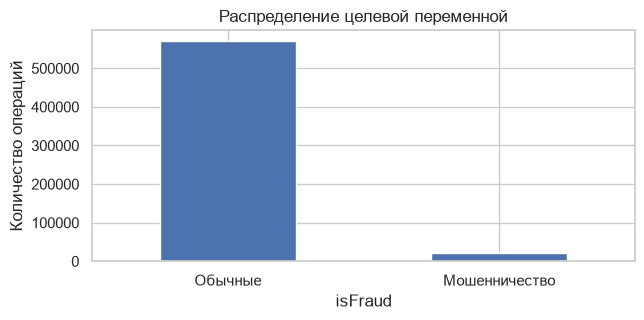

In [7]:
counts = train["isFraud"].value_counts().sort_index()
print(counts)
print((100 * counts / len(train)).round(2).astype(str) + "%")
counts.rename(index={0: "Обычные", 1: "Мошенничество"}).plot.bar(figsize=(7, 3))
plt.title("Распределение целевой переменной")
plt.ylabel("Количество операций")
plt.xticks(rotation=0)
plt.show()

Мошеннических операций 20 663 из 590 540 (3,50%). Для оценки качества требуется метрика, учитывающая прикладную задачу. Стоимость пропущенного мошенничества и ошибочной блокировки в данных не указана, поэтому определить оптимальный порог без дополнительных требований нельзя.


## 3. Пропуски и неполная информация

Проверяются пропуски во всех столбцах транзакций, признаки с постоянными значениями и доступность дополнительных сведений об устройствах и пользователях.

In [8]:
missing_count = None
rows = 0
values = {}
with archive.open("train_transaction.csv") as file:
    for part in pd.read_csv(file, chunksize=20_000):
        current = part.isna().sum()
        missing_count = current if missing_count is None else missing_count.add(current)
        rows += len(part)
        for col in part.columns:
            if len(values.get(col, set())) < 2:
                values.setdefault(col, set()).update(part[col].dropna().unique()[:2])

missing_pct = 100 * missing_count / rows
print("Столбцов с >50% пропусков:", int((missing_pct > 50).sum()))
print("Столбцов с >90% пропусков:", int((missing_pct > 90).sum()))
display(missing_pct.sort_values(ascending=False).head(15).round(2).to_frame("Пропуски, %"))

Столбцов с >50% пропусков: 174
Столбцов с >90% пропусков: 2


,"Пропуски, %"
dist2,93.63
D7,93.41
D13,89.51
D14,89.47
D12,89.04
D6,87.61
D9,87.31
D8,87.31
V153,86.12
V149,86.12


In [9]:
all_empty = [col for col, found in values.items() if len(found) == 0]
constant = [col for col, found in values.items() if len(found) == 1]
print("Полностью пустые признаки:", all_empty)
print("Постоянные признаки:", constant)

Полностью пустые признаки: []
Постоянные признаки: []


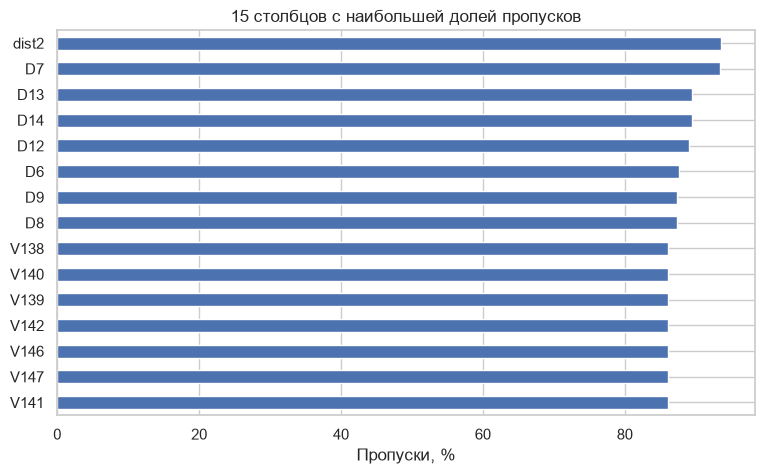

In [10]:
missing_pct.nlargest(15).sort_values().plot.barh(figsize=(9, 5))
plt.title("15 столбцов с наибольшей долей пропусков")
plt.xlabel("Пропуски, %")
plt.show()

In [11]:
for prefix in ["C", "D", "V"]:
    family = [c for c in missing_pct.index if c.startswith(prefix) and c[1:].isdigit()]
    print(prefix, "- признаков:", len(family),
          "| средняя доля пропусков, %:", round(missing_pct[family].mean(), 2))


C - признаков: 14 | средняя доля пропусков, %: 0.0
D - признаков: 15 | средняя доля пропусков, %: 58.15
V - признаков: 339 | средняя доля пропусков, %: 43.04


### Пропуски по классам и типам операций

Сравнивается доля пропусков у обычных и мошеннических операций. Отдельно проверяется, как доступность признаков зависит от типа продукта. Такие различия могут влиять на состав обучающих данных.


In [12]:
missing_fields = ["M1", "V200", "dist1", "R_emaildomain", "D4"]
missing_by_class = train.groupby("isFraud")[missing_fields].agg(lambda x: 100 * x.isna().mean())
display(missing_by_class.T.round(2))


isFraud,0,1
M1,45.06,69.31
V200,77.41,46.43
dist1,59.02,76.99
R_emaildomain,77.88,45.67
D4,28.57,29.50


In [13]:
product_fields = ["M1", "V200", "R_emaildomain", "D4"]
missing_by_product = train.groupby("ProductCD")[product_fields].agg(lambda x: 100 * x.isna().mean())
display(missing_by_product.T.round(2))


ProductCD,C,H,R,S,W
M1,100.00,100.00,100.00,100.00,27.35
V200,12.60,2.71,3.11,3.00,100.00
R_emaildomain,3.14,32.77,0.03,5.07,100.00
D4,6.08,94.31,88.49,100.00,20.16


Пропуски распределены неравномерно. Например, `M1` отсутствует у всех транзакций типов `C`, `H`, `R`, `S`, а `V200` отсутствует у всех транзакций типа `W`. Различия между классами нельзя считать независимыми от состава продуктов.


В исходной таблице 174 столбца имеют более 50% пропусков, два столбца - более 90%. У `dist2` пропущено 93,63% значений, у `D7` - 93,41%. Высокая доля пропусков не означает, что признак следует автоматически удалять. Отсутствие значений может зависеть от типа операции или источника информации.
 Полностью пустых и постоянных столбцов не обнаружено.

### Сведения об устройствах и пользователях

Таблица `identity` содержит дополнительные сведения о части операций и связывается с транзакциями по `TransactionID`. Проверяются уникальность ключей и различия в долях мошенничества между операциями с дополнительной информацией и без неё.


In [14]:
print("Повторы TransactionID в транзакциях:", train["TransactionID"].duplicated().sum())
print("Повторы TransactionID в identity:", identity["TransactionID"].duplicated().sum())
train["has_identity"] = train["TransactionID"].isin(identity["TransactionID"])
print("Доля с identity, %:", round(100 * train["has_identity"].mean(), 2))
display(train.groupby("has_identity")["isFraud"].agg(["size", "mean"]).round(4))

Повторы TransactionID в транзакциях: 0
Повторы TransactionID в identity: 0
Доля с identity, %: 24.42


,size,mean
has_identity,,
False,446307,0.0209
True,144233,0.0785


In [15]:
print("Наличие identity по типам операций, %:")
display((100 * pd.crosstab(train["ProductCD"], train["has_identity"],
                             normalize="index")).round(2))

Наличие identity по типам операций, %:


has_identity,False,True
ProductCD,,
C,9.23,90.77
H,0.35,99.65
R,0.40,99.60
S,0.37,99.63
W,100.00,0.00


In [16]:
identity_missing = (100 * identity.isna().mean()).sort_values(ascending=False)
display(identity_missing.head(12).round(2).to_frame("Пропуски, %"))
print("Типы устройств:")
display(identity["DeviceType"].value_counts(dropna=False).head(10))

,"Пропуски, %"
id_24,96.71
id_25,96.44
id_07,96.43
id_08,96.43
id_21,96.42
id_26,96.42
id_23,96.42
id_27,96.42
id_22,96.42
id_18,68.72


Типы устройств:


DeviceType
desktop    85165
mobile     55645
NaN         3423
Name: count, dtype: int64

Записи `identity` есть у 24,42% транзакций. Доля мошенничества среди них составляет 7,85%, среди остальных - 2,09%. Удаление транзакций без `identity` приведёт к изменению состава обучающей выборки. Наблюдаемая связь не доказывает причинного влияния наличия дополнительных данных.
 При этом наличие `identity` зависит от `ProductCD`: для `W` дополнительные записи отсутствуют, а для `H`, `R` и `S` покрытие превышает 99%. Поэтому наблюдаемая разница в долях мошенничества связана в том числе с составом типов операций.

## 4. Ошибки, выбросы и распределения

Проверяются распределение сумм транзакций, редкие категории и высокая кардинальность. Крупные суммы рассматриваются как потенциально необычные наблюдения, а не как автоматически ошибочные значения.


In [17]:
print("Уникальных card1:", train["card1"].nunique())
print("Сумма транзакции:")
display(train["TransactionAmt"].describe(percentiles=[.5, .95, .99]).round(2))
print("Полностью пустые TransactionAmt:", int(train["TransactionAmt"].isna().sum()))

Уникальных card1: 13553
Сумма транзакции:


count    590540.00
mean        135.03
std         239.16
min           0.25
50%          68.77
95%         445.00
99%        1104.00
max       31937.39
Name: TransactionAmt, dtype: float64

Полностью пустые TransactionAmt: 0


In [18]:
print("Отрицательные суммы транзакций:", (train["TransactionAmt"] < 0).sum())
print("Нулевые суммы транзакций:", (train["TransactionAmt"] == 0).sum())
fields = ["TransactionDT", "TransactionAmt", "ProductCD", "card1", "card4"]
print("Повторы сочетания выбранных полей:", train[fields].duplicated().sum())

Отрицательные суммы транзакций: 0
Нулевые суммы транзакций: 0
Повторы сочетания выбранных полей: 64


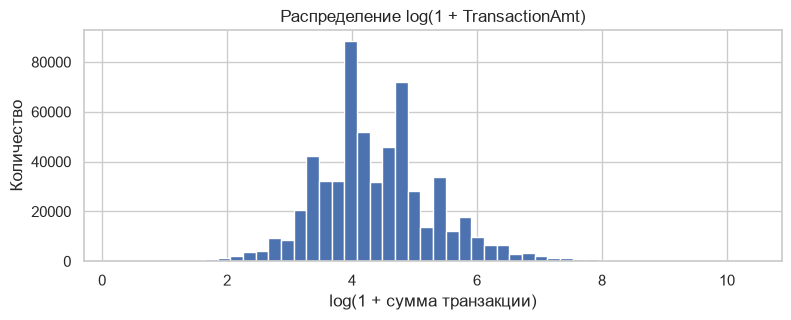

In [19]:
plt.figure(figsize=(9, 3))
plt.hist(np.log1p(train["TransactionAmt"].dropna()), bins=50)
plt.title("Распределение log(1 + TransactionAmt)")
plt.xlabel("log(1 + сумма транзакции)")
plt.ylabel("Количество")
plt.show()

### Суммы операций по классам

Сравниваются основные характеристики сумм у обычных и мошеннических операций. Для графика используются логарифмы сумм, а распределения нормируются отдельно по каждому классу.


In [20]:
display(train.groupby("isFraud")["TransactionAmt"].agg(["count", "median", "mean"]).round(2))


,count,median,mean
isFraud,,,
0,569877,68.5,134.51
1,20663,75.0,149.24


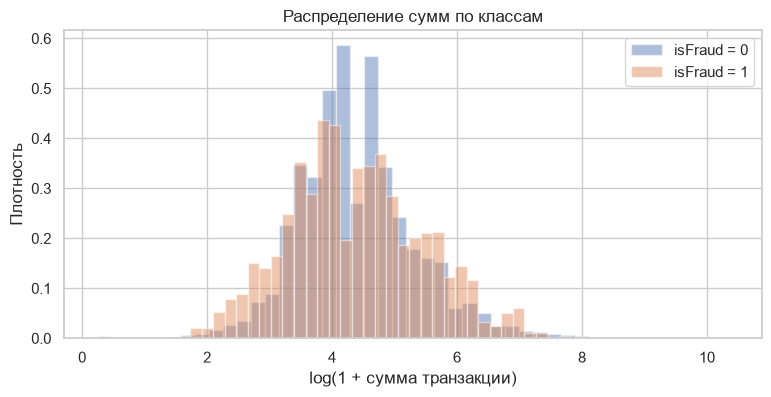

In [21]:
plt.figure(figsize=(9, 4))
for label in [0, 1]:
    amounts = np.log1p(train.loc[train["isFraud"] == label, "TransactionAmt"].dropna())
    plt.hist(amounts, bins=45, density=True, alpha=0.45, label=f"isFraud = {label}")
plt.title("Распределение сумм по классам")
plt.xlabel("log(1 + сумма транзакции)")
plt.ylabel("Плотность")
plt.legend()
plt.show()


,size,mean,fraud_pct
ProductCD,,,
W,439670,0.020399,2.04
C,68519,0.116873,11.69
R,37699,0.037826,3.78
H,33024,0.047662,4.77
S,11628,0.058996,5.90


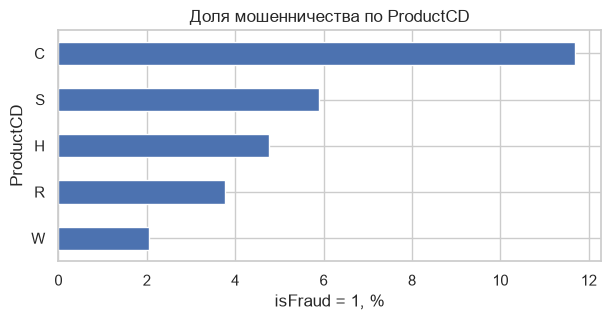

In [22]:
product = train.groupby("ProductCD")["isFraud"].agg(["size", "mean"])
product["fraud_pct"] = (100 * product["mean"]).round(2)
display(product.sort_values("size", ascending=False))
product["fraud_pct"].sort_values().plot.barh(figsize=(7, 3))
plt.title("Доля мошенничества по ProductCD")
plt.xlabel("isFraud = 1, %")
plt.show()

In [23]:
categories = ["ProductCD", "card4", "card6", "P_emaildomain", "R_emaildomain"]
print("Число категорий:")
display(train[categories].nunique(dropna=True).to_frame("Значений"))

print("Доля мошенничества по платёжной системе:")
card4_fraud = train.groupby("card4")["isFraud"].agg(["size", "mean"])
card4_fraud["fraud_pct"] = (100 * card4_fraud["mean"]).round(2)
display(card4_fraud.round(2))


Число категорий:


,Значений
ProductCD,5
card4,4
card6,4
P_emaildomain,59
R_emaildomain,60


Доля мошенничества по платёжной системе:


,size,mean,fraud_pct
card4,,,
american express,8328,0.03,2.87
discover,6651,0.08,7.73
mastercard,189217,0.03,3.43
visa,384767,0.03,3.48


### Редкие значения категориальных признаков

Для `card1` проверяются редко встречающиеся значения и концентрация наблюдений в наиболее частых категориях. Редкие значения не обязательно являются ошибками.


In [24]:
card_counts = train["card1"].value_counts(dropna=True)
print("Всего значений card1:", len(card_counts))
print("Значений с одной транзакцией:", int((card_counts == 1).sum()))
print("Доля операций в 100 наиболее частых значениях, %:",
      round(100 * card_counts.head(100).sum() / card_counts.sum(), 2))
display(card_counts.head(10).to_frame("Количество операций"))


Всего значений card1: 13553
Значений с одной транзакцией: 3444
Доля операций в 100 наиболее частых значениях, %: 47.43


,Количество операций
card1,
7919,14932
9500,14162
15885,10361
17188,10344
15066,7945
12695,7091
12544,6773
6019,6771
2803,6141


У `card1` обнаружено 13 553 различных значений. Доля мошенничества также различается между категориями `ProductCD`: например, для `W` она составляет около 2,04%, для `C` - 11,69%. Эти различия не позволяют сделать вывод о причинном влиянии типа продукта.
 У `P_emaildomain` 59 значений, у `R_emaildomain` 60. В проверяемых столбцах `TransactionAmt` не выявлено нулевых и отрицательных значений. Повторы сочетаний отдельных признаков не следует считать полными дубликатами транзакций.

## 5. Временная структура

В `TransactionDT` задано относительное время операции. Проверяются длительность периода наблюдений и доля мошенничества в последовательных интервалах по 30 дней. Последний интервал может быть неполным.


In [25]:
print("Минимальное время:", train["TransactionDT"].min())
print("Максимальное время:", train["TransactionDT"].max())
print("Период наблюдения, дней:",
      round((train["TransactionDT"].max() - train["TransactionDT"].min()) / 86400, 1))
period = train["TransactionDT"] // (30 * 86400)
monthly = train.groupby(period)["isFraud"].agg(["size", "mean"])
monthly["fraud_pct"] = (100 * monthly["mean"]).round(2)
display(monthly)

Минимальное время: 86400
Максимальное время: 15811131
Период наблюдения, дней: 182.0


,size,mean,fraud_pct
TransactionDT,,,
0,130968,0.024762,2.48
1,89838,0.040373,4.04
2,91768,0.040319,4.03
3,98027,0.039265,3.93
4,85303,0.034723,3.47
5,86525,0.034013,3.40
6,8111,0.041795,4.18


In [26]:
print("Покрытие identity по 30-дневным интервалам:")
display(train.groupby(period)["has_identity"].agg(["size", "mean"]).round(3))
print("Доля мошенничества по периодам и типам продукта, %:")
display((100 * train.pivot_table(index=period, columns="ProductCD",
                                 values="isFraud", aggfunc="mean")).round(2))

Покрытие identity по 30-дневным интервалам:


,size,mean
TransactionDT,,
0,130968,0.436
1,89838,0.186
2,91768,0.189
3,98027,0.186
4,85303,0.177
5,86525,0.211
6,8111,0.181


Доля мошенничества по периодам и типам продукта, %:


ProductCD,C,H,R,S,W
TransactionDT,,,,,
0,7.97,1.83,0.96,2.46,1.87
1,13.17,13.39,9.54,7.07,2.07
2,12.17,12.81,9.08,10.66,2.14
3,12.61,9.93,6.20,7.85,2.20
4,12.65,5.95,4.96,6.38,2.09
5,13.18,6.30,4.72,4.72,1.82
6,17.78,6.11,7.89,15.68,2.16


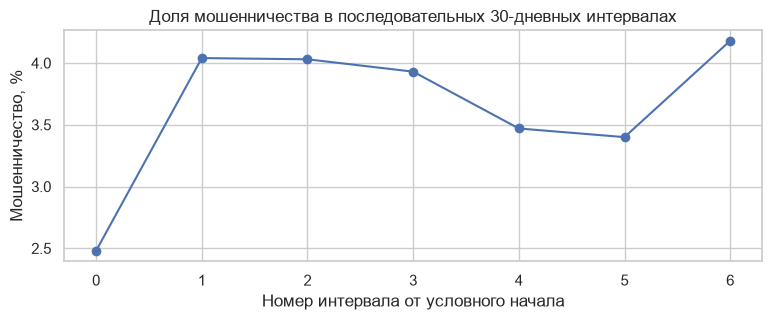

In [27]:
monthly["fraud_pct"].plot(marker="o", figsize=(9, 3))
plt.title("Доля мошенничества в последовательных 30-дневных интервалах")
plt.xlabel("Номер интервала от условного начала")
plt.ylabel("Мошенничество, %")
plt.show()

Доля мошенничества различается по временным интервалам: в первом интервале она составляет около 2,48%, в последующих - 3,40-4,04%. Для задачи прогноза будущих операций следует рассматривать хронологическую валидацию. Изменение долей само по себе не доказывает причины сдвига.
 Покрытие `identity` также меняется: 43,6% в первом интервале против 17,7-21,1% в последующих.

## 6. Сравнение train/test

Проверяются соответствие схем, различия в пропусках основных групп признаков, распределения категорий и временное положение тестовых наблюдений. Тестовая часть не содержит `isFraud`.

In [28]:
train_cols = set(pd.read_csv(archive.open("train_transaction.csv"), nrows=0).columns)
test_cols = set(pd.read_csv(archive.open("test_transaction.csv"), nrows=0).columns)
train_id_cols = set(pd.read_csv(archive.open("train_identity.csv"), nrows=0).columns)
test_id_cols = set(pd.read_csv(archive.open("test_identity.csv"), nrows=0).columns)

print("Только в train_transaction:", sorted(train_cols - test_cols))
print("Только в test_transaction:", sorted(test_cols - train_cols))
print("Различия в identity:", sorted(train_id_cols - test_id_cols)[:5],
      sorted(test_id_cols - train_id_cols)[:5])


Только в train_transaction: ['isFraud']
Только в test_transaction: []
Различия в identity: ['id_01', 'id_02', 'id_03', 'id_04', 'id_05'] ['id-01', 'id-02', 'id-03', 'id-04', 'id-05']


In [29]:
check_cols = ["D4", "D7", "dist1", "dist2", "R_emaildomain", "P_emaildomain",
              "M1", "M9", "V100", "V200", "V300"]
select = ["TransactionID", "TransactionDT", "ProductCD"] + check_cols
train_ids = pd.Index(train["TransactionID"])
test_n, test_overlap = 0, 0
test_missing = pd.Series(0, index=check_cols, dtype="int64")
test_products = pd.Series(dtype="int64")
first_dt, last_dt = float("inf"), float("-inf")

with archive.open("test_transaction.csv") as file:
    for block in pd.read_csv(file, usecols=select, chunksize=20_000):
        test_n += len(block)
        test_overlap += int(block["TransactionID"].isin(train_ids).sum())
        test_missing += block[check_cols].isna().sum()
        test_products = test_products.add(block["ProductCD"].value_counts(), fill_value=0)
        first_dt = min(first_dt, block["TransactionDT"].min())
        last_dt = max(last_dt, block["TransactionDT"].max())

print("Тестовых транзакций:", test_n)
print("Совпадающих TransactionID:", test_overlap)
print("Разрыв по времени, дней:", round((first_dt - train["TransactionDT"].max()) / 86400, 2))

Тестовых транзакций: 506691
Совпадающих TransactionID: 0
Разрыв по времени, дней: 30.0


In [31]:
compare_missing = pd.DataFrame({
    "train, %": (100 * train[check_cols].isna().mean()).round(2),
    "test, %": (100 * test_missing[check_cols] / test_n).round(2)
})
display(compare_missing)
print("Доли ProductCD в train/test, %:")
display(pd.concat([train["ProductCD"].value_counts(normalize=True) * 100,
                   test_products / test_n * 100],
                  axis=1, keys=["train", "test"]).round(2))

,"train, %","test, %"
D4,28.60,15.17
D7,93.41,88.13
dist1,59.65,57.47
dist2,93.63,92.81
R_emaildomain,76.75,73.18
P_emaildomain,15.99,13.66
M1,45.91,34.86
M9,58.63,46.38
V100,0.05,0.00
V200,76.32,73.09


Доли ProductCD в train/test, %:


,train,test
ProductCD,,
W,74.45,71.24
C,11.60,13.67
R,6.38,7.04
H,5.59,5.80
S,1.97,2.25


### Распределение сумм train/test

Сравниваются квантильные характеристики суммы транзакции. Это дополняет проверку пропусков и распределения категорий.


In [32]:
test_amount = pd.read_csv(archive.open("test_transaction.csv"), usecols=["TransactionAmt"])
levels = [0.5, 0.95, 0.99]
amount_compare = pd.DataFrame({
    "train": train["TransactionAmt"].quantile(levels),
    "test": test_amount["TransactionAmt"].quantile(levels)
})
amount_compare.index = ["Медиана", "95-й процентиль", "99-й процентиль"]
display(amount_compare.round(2))


,train,test
Медиана,68.77,67.95
95-й процентиль,445.00,439.70
99-й процентиль,1104.00,1104.00


In [33]:
difference = (compare_missing["test, %"] - compare_missing["train, %"]).abs()
print("Различия доли пропусков среди проверяемых признаков:")
display(difference.sort_values(ascending=False).round(2).to_frame("Разница, п.п."))

Различия доли пропусков среди проверяемых признаков:


,"Разница, п.п."
D4,13.43
M9,12.25
M1,11.05
D7,5.28
R_emaildomain,3.57
V200,3.23
P_emaildomain,2.33
dist1,2.18
V300,0.98
dist2,0.82


Между концом train и началом test наблюдается разрыв около 30 дней. У `D4` доля пропусков составляет 28,60% в train и 15,17% в test. Есть различия и в распределении категорий `ProductCD`. В дополнительных таблицах используются разные обозначения столбцов `id_01` и `id-01`, поэтому перед объединением требуется согласовать названия.
 После замены дефиса на подчёркивание в названиях `id-*` схемы таблиц `identity` совпадают. Покрытие `identity` в тестовой части составляет 28,01%.

In [34]:
test_identity = pd.read_csv(archive.open("test_identity.csv"))
test_identity = test_identity.rename(columns=lambda name: name.replace("id-", "id_"))
print("Совпадают ли схемы identity после переименования:",
      set(identity.columns) == set(test_identity.columns))
print("Покрытие identity в test, %:", round(100 * len(test_identity) / test_n, 2))
identity_diff = (100 * identity.isna().mean() - 100 * test_identity.isna().mean()).abs()
display(identity_diff.nlargest(10).round(2).to_frame("Разница пропусков, п.п."))

Совпадают ли схемы identity после переименования: True
Покрытие identity в test, %: 28.01


,"Разница пропусков, п.п."
id_14,5.21
id_18,4.57
id_32,3.99
id_30,3.99
id_13,3.54
id_34,3.08
id_11,1.36
id_28,1.36
id_29,1.36
id_15,1.22


## 7. Связи признаков с целевой переменной

Рассчитываются корреляции выбранных числовых признаков с `isFraud` и между собой. Для заметных связей дополнительно проверяются число наблюдений и пропуски. Корреляция обезличенного признака сама по себе не доказывает утечку.

V200              0.319
C1                0.031
V300              0.025
TransactionAmt    0.011
V100              0.011
V1                0.001
C13              -0.011
card1            -0.014
D4               -0.067
D15              -0.078
Name: isFraud, dtype: float64

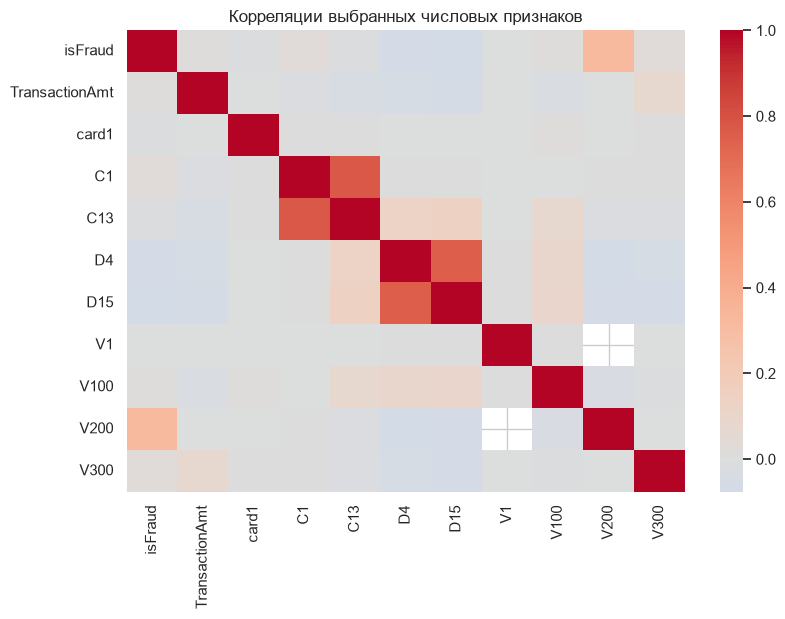

In [35]:
numeric_cols = ["isFraud", "TransactionAmt", "card1", "C1", "C13", "D4", "D15", "V1", "V100", "V200", "V300"]
corr = train[numeric_cols].corr()
display(corr["isFraud"].drop("isFraud").sort_values(ascending=False).round(3))
plt.figure(figsize=(9, 6))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Корреляции выбранных числовых признаков")
plt.show()

In [36]:
print("Число наблюдений с V200:", train["V200"].notna().sum())
print("Доля мошенничества при наличии и отсутствии V200:")
display(train.groupby(train["V200"].notna())["isFraud"].agg(["size", "mean"]).round(4))
print("Распределение V200:")
display(train["V200"].describe(percentiles=[.5, .95, .99]).round(2))

Число наблюдений с V200: 139819
Доля мошенничества при наличии и отсутствии V200:


,size,mean
V200,,
False,450721,0.0213
True,139819,0.0792


Распределение V200:


count    139819.00
mean          1.12
std           1.25
min           0.00
50%           1.00
95%           2.00
99%           5.00
max          45.00
Name: V200, dtype: float64

## 8. Момент прогнозирования и потенциальные утечки

`V200` имеет заметную корреляцию с таргетом (r около 0,319), но вычислена она по записям с известным значением. Покрытие этого признака также различается между группами операций.

`TransactionID` используется для соединения таблиц. `TransactionDT` задаёт относительное время, а многие признаки скрыты под кодовыми обозначениями. Для проверки допустимости признаков необходимо знать, были ли их значения доступны в момент транзакции. Необычные корреляции и изменения долей пропусков указывают на необходимость проверки, но сами по себе не подтверждают утечку.

## 9. Выводы и эталон для агента

1. Задача - бинарная классификация. Целевой столбец `isFraud`, положительный класс `1` (3,50%).
2. При выборе метрики необходимо учитывать дисбаланс и стоимость ошибок. `roc_auc` может использоваться для оценки ранжирования, но не определяет порог принятия решения.
3. Не следует автоматически исключать признаки с пропусками или транзакции без данных `identity`.
4. Перед соединением таблиц требуется проверить ключ `TransactionID` и согласовать имена столбцов `identity`.
5. При оценке будущих операций необходимо проверять качество на более поздних транзакциях. Конкурсный test не содержит правильных ответов.
6. Для числовых и категориальных групп признаков следует учитывать разнообразие значений, пропуски и возможные изменения распределений.
7. Доступность части обезличенных признаков на момент прогноза неизвестна. По одной корреляции нельзя установить наличие утечки.
8. Объединение транзакций и `identity` относится к подготовке данных перед передачей в AutoGluon.

IEEE-CIS Fraud Detection позволяет исследовать редкий класс, неполную информацию, большое число признаков, временную зависимость и различия train/test.